# Lab 8, Part 1: Profiling

**Baseline:** `loop_based_mosaic` from my Lab 1 `app.py`, copied unchanged into `baseline/lab1_baseline.py`.

Dependencies are pinned in `requirements-dev.txt` and installed with `uv pip install -r requirements-dev.txt` (in place of `pip install line_profiler`).

In [1]:
%load_ext line_profiler

import cProfile
import io
import platform
import pstats
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from skimage import data

from baseline.lab1_baseline import loop_based_mosaic

Path("results").mkdir(exist_ok=True)
Path("test_images").mkdir(exist_ok=True)
print(platform.platform(), "| Python", platform.python_version(), "| numpy", np.__version__)

macOS-27.2.1-arm64-arm-64bit | Python 3.12.7 | numpy 2.5.3


## Test suite

Images: scikit-image's astronaut photo at 256, 512 and 1024 px (the 1024 is upscaled, which doesn't affect timing). Grids: 16, 32, 64. Tiles: Lab 1's 32-color synthetic palette.

In [2]:
IMAGE_SIZES, GRID_SIZES = [256, 512, 1024], [16, 32, 64]
REQUIRED = {(256, 16), (512, 32), (1024, 64)}

images = {}
for size in IMAGE_SIZES:
    path = Path(f"test_images/astronaut_{size}.png")
    if not path.exists():
        Image.fromarray(data.astronaut()).resize((size, size), Image.LANCZOS).save(path)
    images[size] = np.array(Image.open(path).convert("RGB"))

# Lab 1's tile set (same lines as in Lab 1's process_image)
num_tiles, tile_size = 32, 20
np.random.seed(42)
base_colors = np.random.randint(0, 255, size=(num_tiles, 3), dtype=np.uint8)
tile_array = np.zeros((num_tiles, tile_size, tile_size, 3), dtype=np.uint8)
for i in range(num_tiles):
    tile_array[i, :, :] = base_colors[i]
    tile_array[i, 0, :] = 20
    tile_array[i, :, 0] = 20

## Baseline timing

5 timed runs per configuration, after one untimed run.

In [3]:
def time_runs(img, grid, n=5):
    loop_based_mosaic(img, grid, tile_array, base_colors)  # untimed first run (cold caches)
    times = []
    for _ in range(n):
        start = time.perf_counter()
        loop_based_mosaic(img, grid, tile_array, base_colors)
        times.append(time.perf_counter() - start)
    return np.array(times)


rows = []
for size in IMAGE_SIZES:
    for grid in GRID_SIZES:
        t = time_runs(images[size], grid)
        rows.append({"image": size, "grid": grid, "cells": grid * grid,
                     "mean_s": t.mean(), "std_s": t.std(ddof=1), "min_s": t.min(),
                     "required": "✓" if (size, grid) in REQUIRED else ""})
timings = pd.DataFrame(rows)
timings.to_csv("results/baseline_timings.csv", index=False)
timings.round(4)

,image,grid,cells,mean_s,std_s,min_s,required
0,256,16,256,0.0186,0.0000,0.0185,✓
1,256,32,1024,0.0714,0.0004,0.0709,
2,256,64,4096,0.2910,0.0021,0.2882,
3,512,16,256,0.0212,0.0001,0.0211,
4,512,32,1024,0.0748,0.0007,0.0743,✓
5,512,64,4096,0.2979,0.0014,0.2964,
6,1024,16,256,0.0319,0.0003,0.0316,
7,1024,32,1024,0.0863,0.0013,0.0849,
8,1024,64,4096,0.3109,0.0027,0.3070,✓


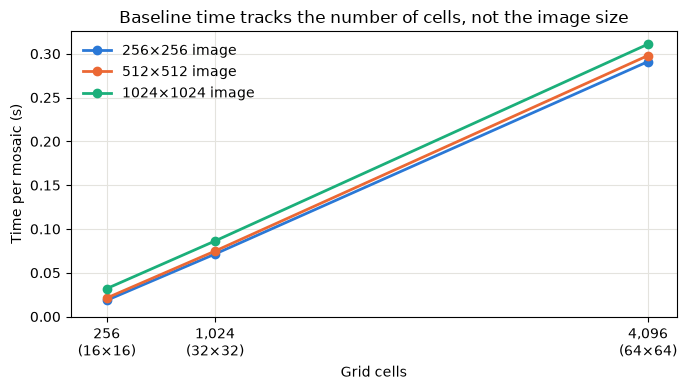

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for (size, grp), color in zip(timings.groupby("image"), ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.plot(grp.cells, grp.mean_s, marker="o", lw=2, color=color, label=f"{size}×{size} image")
ax.set(xlim=(0, 4300), ylim=(0, None), xlabel="Grid cells", ylabel="Time per mosaic (s)",
       title="Baseline time tracks the number of cells, not the image size")
ax.set_xticks([256, 1024, 4096], ["256\n(16×16)", "1,024\n(32×32)", "4,096\n(64×64)"])
ax.grid(color="#e4e3de")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("results/baseline_scaling.png", dpi=200)
plt.show()

Time grows almost linearly with the number of cells and barely with image size, so the cost is per-cell Python overhead, not pixel math. 512×512 / 32×32 takes about 0.075 s, so 20× means getting under 3.75 ms.

## cProfile (512×512, 32×32)

In [5]:
img512 = images[512]
prof = cProfile.Profile()
prof.runcall(loop_based_mosaic, img512, 32, tile_array, base_colors)
stream = io.StringIO()
pstats.Stats(prof, stream=stream).strip_dirs().sort_stats("tottime").print_stats(10)
print(stream.getvalue())

         273793 function calls (273792 primitive calls) in 0.146 seconds

   Ordered by: internal time
   List reduced from 78 to 10 due to restriction <10>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.046    0.046    0.142    0.142 lab1_baseline.py:30(loop_based_mosaic)
    32768    0.040    0.000    0.082    0.000 _linalg.py:2598(norm)
    32768    0.021    0.000    0.021    0.000 {method 'dot' of 'numpy.ndarray' objects}
     1024    0.007    0.000    0.007    0.000 {method 'reduce' of 'numpy.ufunc' objects}
    32768    0.007    0.000    0.007    0.000 {method 'ravel' of 'numpy.ndarray' objects}
    66560    0.006    0.000    0.006    0.000 {built-in method builtins.issubclass}
    32768    0.005    0.000    0.008    0.000 _linalg.py:168(isComplexType)
    32768    0.003    0.000    0.003    0.000 {built-in method numpy.asarray}
     1024    0.003    0.000    0.012    0.000 _methods.py:115(_mean)
    32768    0.003    0.000    0.003    0.0

`np.linalg.norm` (listed as `_linalg.py:2598(norm)`, the NumPy file it's defined in) is called 32,768 times (1,024 cells × 32 tiles) and takes over half the run, almost all of it call overhead on 3-element vectors. `np.mean` is called once per cell. There's no file I/O.

## line_profiler: `loop_based_mosaic` (512×512, 32×32)

`%lprun` output goes to Jupyter's pager, which isn't saved in the notebook, so `-T` writes it to a file that's printed below.

In [6]:
%lprun -u 1e-3 -T results/lprun_loop_based_mosaic.txt -f loop_based_mosaic loop_based_mosaic(img512, 32, tile_array, base_colors)
print(Path("results/lprun_loop_based_mosaic.txt").read_text())


*** Profile printout saved to text file 'results/lprun_loop_based_mosaic.txt'.
Timer unit: 0.001 s

Total time: 0.356736 s
File: /Users/robertwzhou/Documents/GitHub/ImageMosaicGenerator/baseline/lab1_baseline.py
Function: loop_based_mosaic at line 30

Line #      Hits         Time  Per Hit   % Time  Line Contents
    30                                           def loop_based_mosaic(img_array, grid_size, tile_array, base_colors):
    31         1          0.0      0.0      0.0      height, width, channels = img_array.shape
    32         1          0.0      0.0      0.0      tile_h, tile_w = height // grid_size, width // grid_size
    33         1          0.0      0.0      0.0      display_tile_size = tile_array.shape[1]
    34                                               
    35         1          0.0      0.0      0.0      final_img = np.zeros((grid_size * display_tile_size, grid_size * display_tile_size, 3), dtype=np.uint8)
    36                                               
  

Line 48, `dist = np.linalg.norm(avg_color - color)` in the inner tile loop, takes about 87% of the function. The per-cell `np.mean` (line 43) is about 6%. Line numbers are the same as in `app.py`.

## Bottlenecks to fix in Part 2

| # | Bottleneck | Evidence | Fix |
|---|---|---|---|
| 1 | One `np.linalg.norm` call per cell per tile (line 48) | 32,768 calls, ~87% of function time | One broadcast distance computation + `argmin` (or `cKDTree`) |
| 2 | Python loop over cells with a separate `np.mean` each (lines 37–43) | 1,024 iterations, ~6% in `np.mean` alone | Reshape to `(grid, cell, grid, cell, 3)` and average all cells at once |
| 3 | Tile pasted one cell at a time (line 55) | 1,024 slice assignments | Index `tile_array` with the chosen-tile grid, then reshape |
| 4 | Redundant work per request | Lab 1's handler runs this loop only to report its time, and rebuilds the tile set each request | Run only the fast path; load tiles once at startup |